---

# Tugas Besar 2 IF3170 Inteligensi Artifisial


---

## Group 11

- 13524027 Aufa Rienaldifaza Ahmad
- 13524045 Ahmad Zaky Robbani
- 13524075 Hakam Avicena Mustain
- 13524087 Muhammad Fakhry Zaki
- 13524099 Muhammad Akmal

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

Bagian ini merumuskan persoalan menurut pemahaman kelompok.

## Overview

Notebook ini merupakan pengerjaan Tugas Besar 2 IF3170 Inteligensi Artifisial. Persoalan yang diselesaikan adalah memprediksi apakah suatu pesanan penginapan akan dibatalkan (`is_canceled`) berdasarkan 17 atribut pemesanan, seperti komposisi tamu, lama menginap, paket kamar dan makanan, waktu kedatangan, saluran pemesanan, riwayat tamu, dan harga per malam. Prediksi pembatalan sejak awal dapat membantu pihak penginapan merencanakan ketersediaan kamar dan tindak lanjut terhadap pesanan yang berisiko dibatalkan.

## Aim

1. Mengimplementasikan lima algoritma *supervised learning* dari nol pada pustaka `ml_lib`, yaitu KNN, Decision Tree Learning, Logistic Regression, SVM, dan Naive Bayes.
2. Menyusun *pipeline* pra-pemrosesan yang bebas kebocoran data, dengan seluruh statistik dipelajari dari data latih saja.
3. Mengevaluasi setiap model dengan *holdout* dan *stratified 5-fold cross-validation*, lalu membandingkannya dengan padanan pada `scikit-learn`.
4. Menghasilkan berkas submisi Kaggle dari model dengan kinerja terbaik.

## Metric

Metrik utama adalah *macro-F1*, yaitu rata-rata F1 dari kedua kelas:

$$F1_c = \frac{2 P_c R_c}{P_c + R_c}, \qquad \text{macro-F1} = \frac{F1_0 + F1_1}{2},$$

dengan $P_c$ dan $R_c$ adalah *precision* dan *recall* kelas $c$. Karena data latih tidak seimbang (sekitar 67% tidak dibatalkan dan 33% dibatalkan), akurasi dapat terlihat tinggi walaupun model jarang menebak kelas dibatalkan. *Macro-F1* memberi bobot yang sama pada kedua kelas sehingga kinerja pada kelas minoritas tetap diperhitungkan.

## Dataset

Dataset berisi catatan pemesanan penginapan. Setiap baris menggambarkan satu reservasi dan diidentifikasi oleh `id` heksadesimal yang unik.

| Berkas | Baris | Kolom | Isi |
|---|---|---|---|
| `train.csv` | 27.373 | 19 | Fitur dan target `is_canceled` |
| `test.csv` | 6.844 | 18 | Fitur tanpa target |
| `sample_submission.csv` | 6.844 | 2 | Format submisi (`id`, `is_canceled`) |

Ke-17 fitur terdiri atas tiga atribut kategorikal (`meal_package`, `room_category`, `booking_channel`) serta atribut numerik, biner, dan cacahan lainnya. Delapan kolom memiliki nilai hilang, yaitu `num_adults`, `num_children`, `meal_package`, `needs_parking`, `room_category`, `days_before_arrival`, `nightly_rate_idr`, dan `special_requests`. Distribusi target adalah 18.404 pesanan tidak dibatalkan (67,23%) dan 8.969 pesanan dibatalkan (32,77%).

## Approach

1. **Pemahaman data:** mendeskripsikan atribut, mengeksplorasi distribusi dan hubungannya dengan target, serta memeriksa kualitas data.
2. **Pembagian data:** membagi `train.csv` secara terstratifikasi menjadi 75% data latih dan 25% data validasi sebelum persiapan data dilakukan.
3. **Persiapan data:** membersihkan data, membentuk fitur turunan, melakukan *encoding* dan penskalaan, serta reduksi dimensi untuk model berbasis jarak, seluruhnya dalam satu *pipeline* yang dilatih ulang pada setiap *fold*.
4. **Pemodelan dan validasi:** melatih model buatan sendiri dan mengevaluasinya dengan *holdout* serta *5-fold cross-validation* menggunakan *macro-F1*.
5. **Perbandingan dan penyetelan:** membandingkan dengan model `scikit-learn`, memeriksa kontribusi fitur, dan menyetel hiperparameter.
6. **Submisi dan analisis kesalahan:** melatih model terbaik pada seluruh data latih, membuat berkas submisi, lalu menganalisis kesalahan prediksinya.

---

# Initialization <a name="2"></a>

---

Bagian ini menyiapkan lingkungan, pengaturan, dan berkas data.

## Environment Setup

Sel berikut mencantumkan pustaka dasar yang dibutuhkan. Baris instalasi dibiarkan sebagai komentar secara bawaan.

In [191]:
# %pip install -q numpy pandas
%pip install gdown imbalanced-learn matplotlib numpy pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import Libraries

Seluruh *import* pada notebook ini dikumpulkan dalam sel berikut.

In [192]:
import calendar
import os
import random
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.insert(0, str(Path.cwd() / 'src'))

pd.set_option('display.max_columns', None)

## Settings

*Path* dan konstanta bersama disimpan dalam kelas ini.

In [193]:
class Settings:
    SEED        = 3170
    N_FOLDS     = 5 
    DATA_DIR    = Path('data')
    OUTPUT_DIR  = Path('output')
    ID_COLUMN   = 'id'
    TARGET      = 'is_canceled'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

*Seed* tetap digunakan agar hasil dapat direproduksi.

In [194]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

Berkas kompetisi dibaca pada bagian ini. Kolom `id` tetap dibaca sebagai teks karena sebagian nilainya menyerupai angka.

In [195]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Pemahaman data membangun pengetahuan yang menjadi dasar keputusan pada tahap persiapan data.

## Describe Data

Bagian ini membahas ukuran data, tipe atribut, dan makna setiap kolom.

In [196]:
num_cols = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "arrival_year", "arrival_month", "arrival_day",
    "prior_cancellations", "prior_completed_bookings",
    "nightly_rate_idr", "special_requests"
]
cat_cols = ["meal_package", "room_category", "booking_channel"]
bin_cols = ["needs_parking", "is_returning_guest"]
target_col = "is_canceled"

print('\nTRAIN INFO')
train_df.info()
print('\nTEST INFO')
test_df.info()

train_df.head()


TRAIN INFO
<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returning_guest        27373 non-null  int64  
 14  prior

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


## Explore Data

Bagian ini membahas distribusi atribut serta hubungan antaratribut dan dengan target.

is_canceled
0    18404
1     8969
Name: count, dtype: int64

Target distribution (%)
is_canceled
0    67.23
1    32.77
Name: proportion, dtype: float64


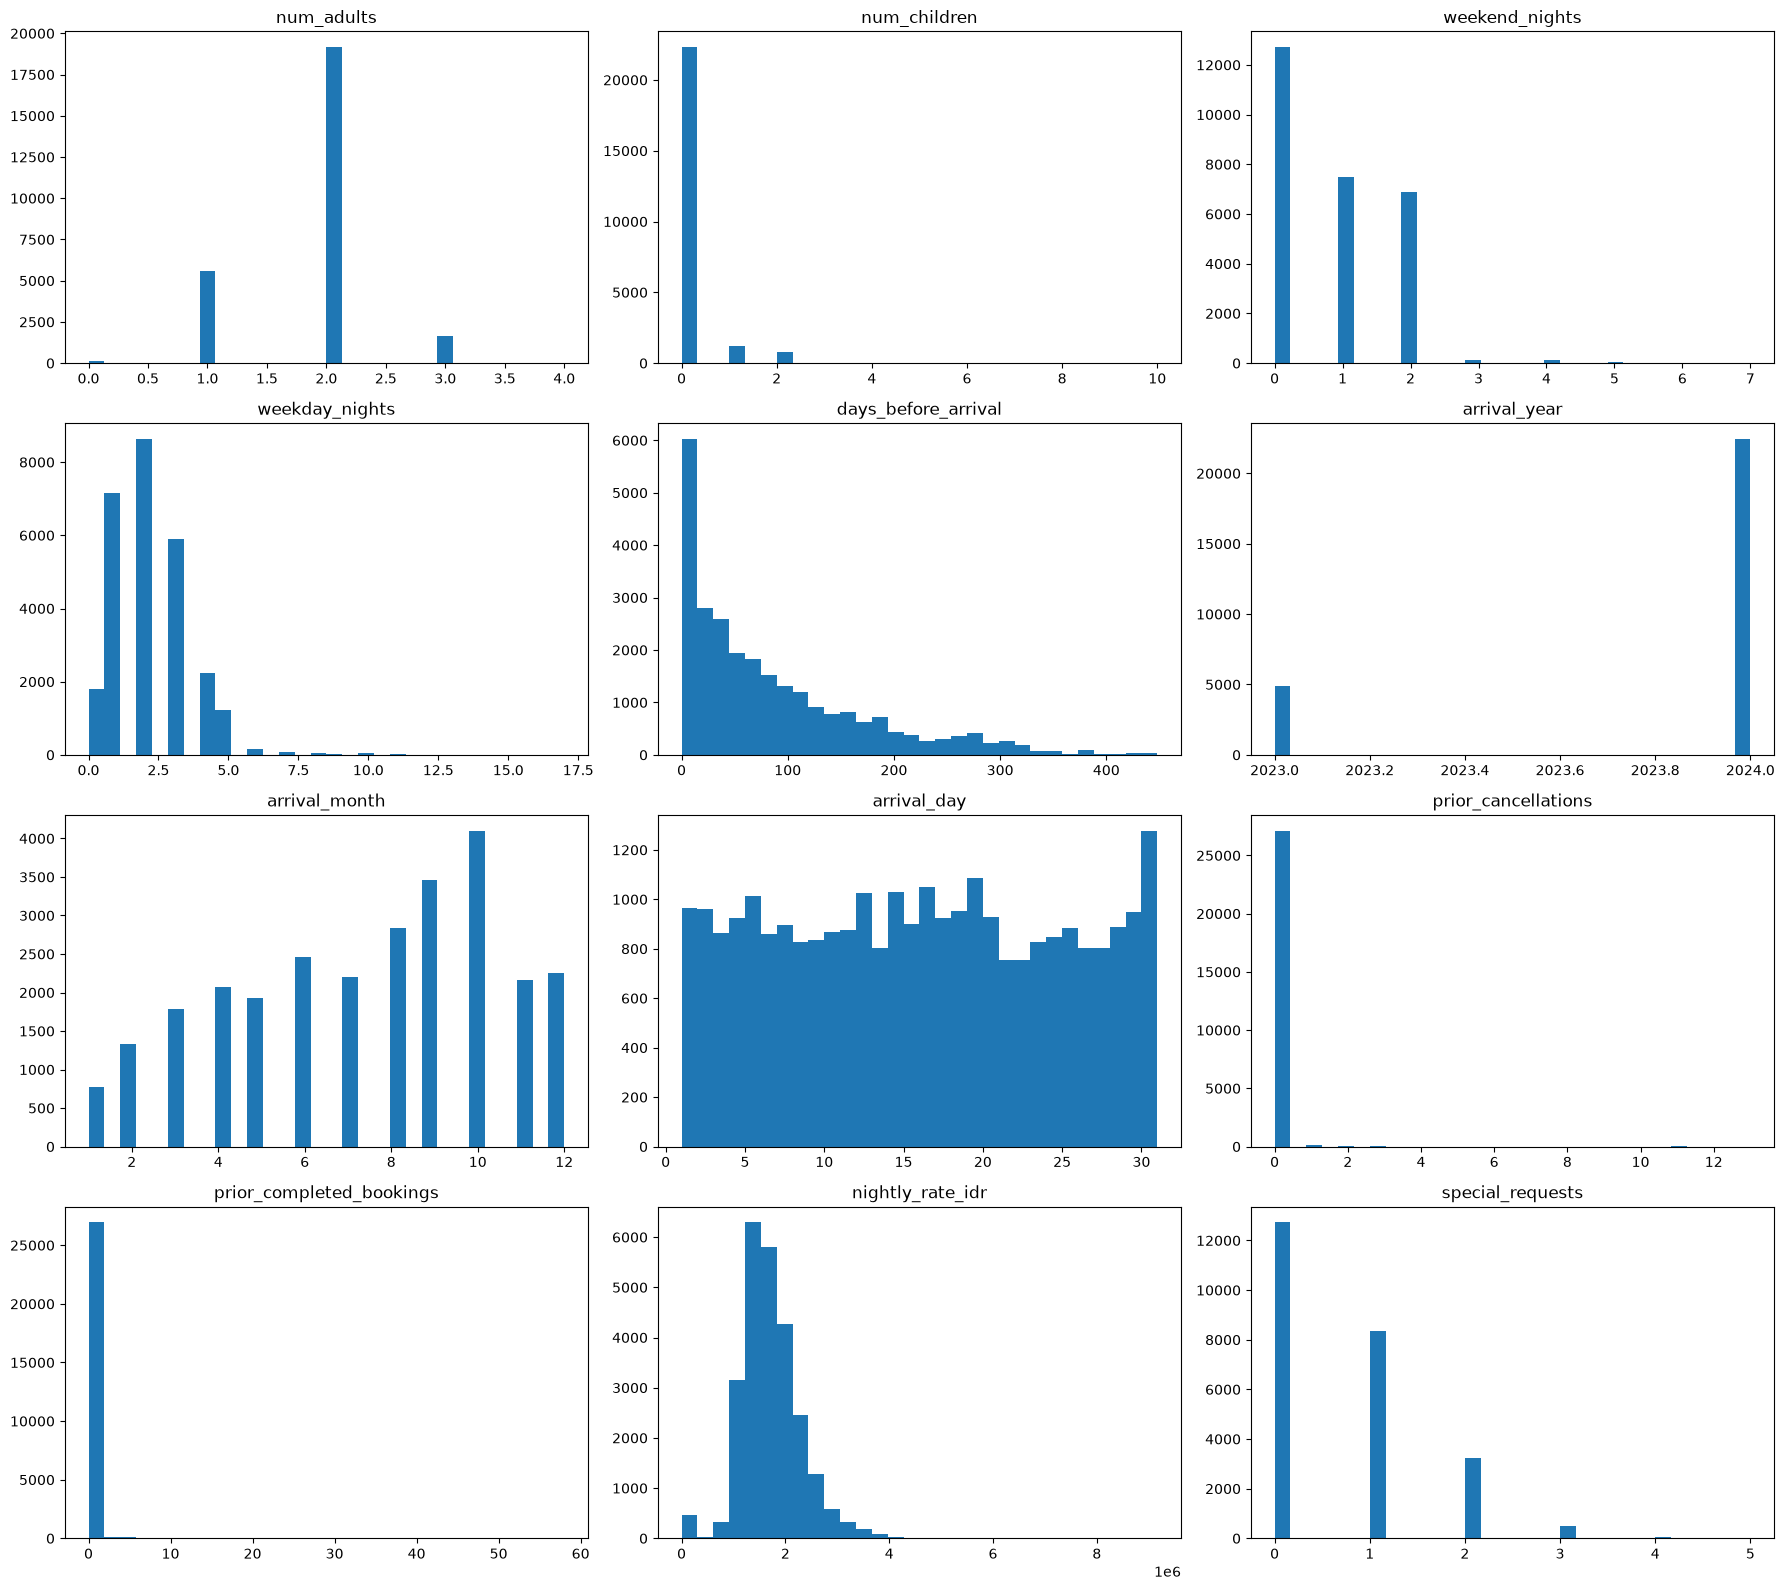

--- meal_package ---
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
NaN            1760
Full Board        4
Name: count, dtype: int64
--- room_category ---
room_category
Type B    20447
Type G     4396
NaN        1002
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64
--- booking_channel ---
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64
--- needs_parking ---
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64
--- is_returning_guest ---
is_returning_guest
0    26684
1      689
Name: count, dtype: int64


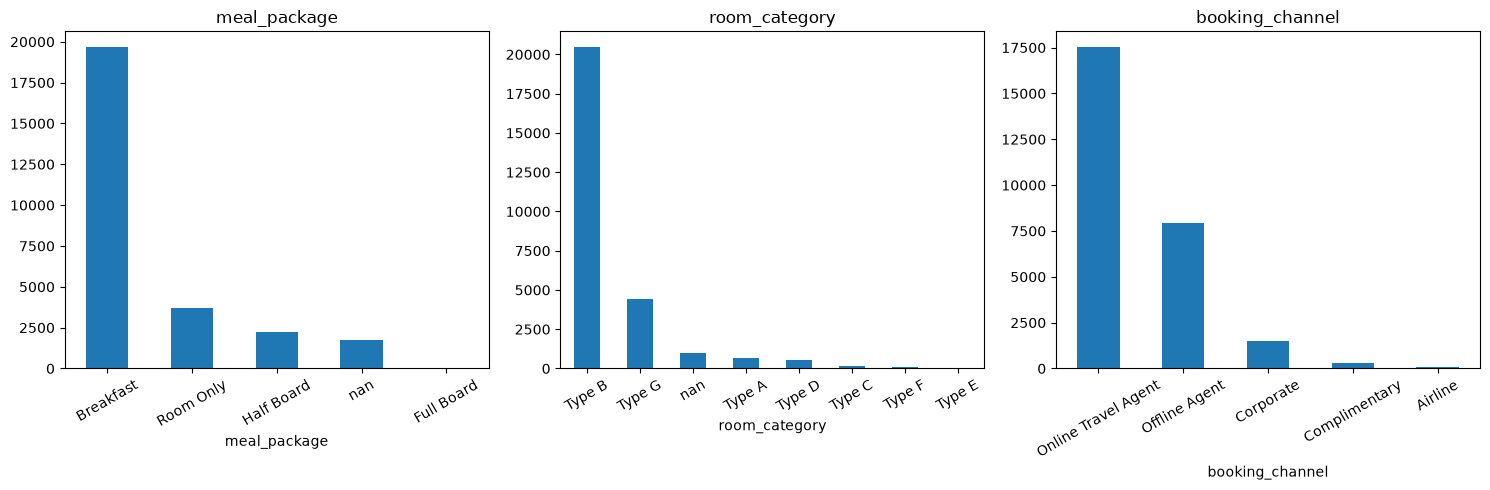


Numeric correlations with target:
days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
special_requests           -0.257996
Name: is_canceled, dtype: float64


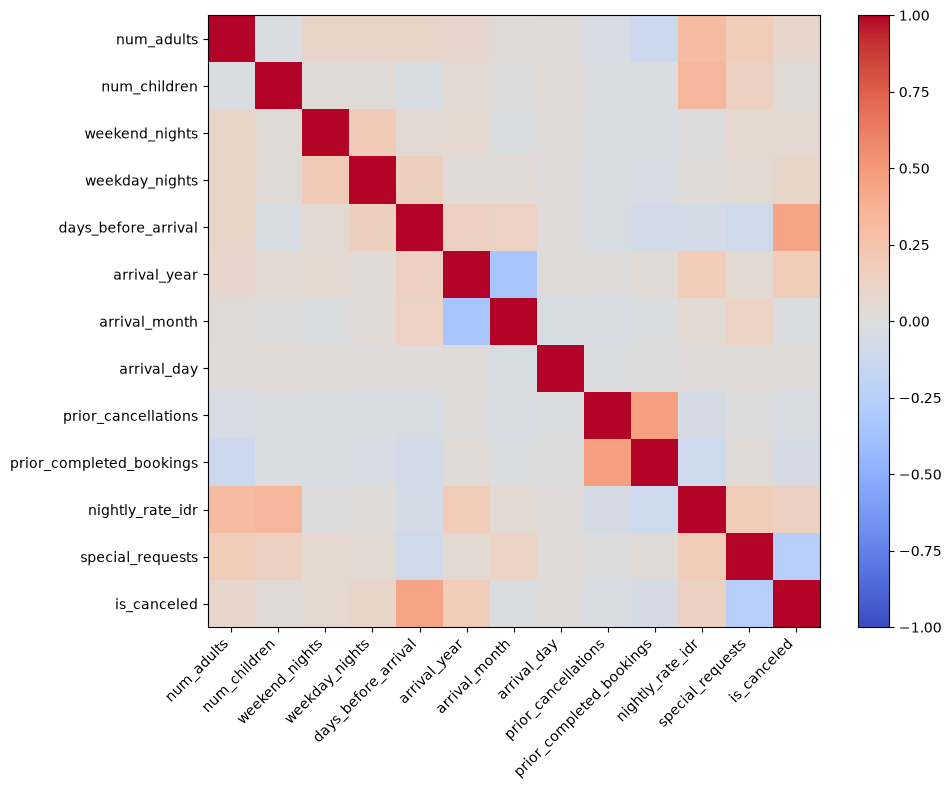


Cancellation rate by meal_package:
meal_package
Half Board    0.459
Room Only     0.338
NaN           0.319
Breakfast     0.311
Full Board    0.250
Name: is_canceled, dtype: float64

Cancellation rate by room_category:
room_category
Type A    0.426
NaN       0.348
Type G    0.342
Type D    0.329
Type B    0.321
Type E    0.286
Type C    0.249
Type F    0.244
Name: is_canceled, dtype: float64

Cancellation rate by booking_channel:
booking_channel
Online Travel Agent    0.364
Airline                0.307
Offline Agent          0.302
Corporate              0.115
Complimentary          0.000
Name: is_canceled, dtype: float64


In [197]:
print(train_df[target_col].value_counts())
print('\nTarget distribution (%)')
print((train_df[target_col].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
for axis, column in zip(axes.flat, num_cols):
    axis.hist(train_df[column].dropna(), bins=30)
    axis.set_title(column)
plt.tight_layout()
plt.show()

for column in cat_cols + bin_cols:
    print(f'--- {column} ---')
    print(train_df[column].value_counts(dropna=False))

fig, axes = plt.subplots(1, len(cat_cols), figsize=(15, 5))
for axis, column in zip(axes, cat_cols):
    train_df[column].value_counts(dropna=False).plot(kind='bar', ax=axis)
    axis.set_title(column)
    axis.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

correlation = train_df[num_cols + [target_col]].corr()
print('\nNumeric correlations with target:')
print(correlation[target_col].drop(target_col).sort_values(ascending=False))
fig, axis = plt.subplots(figsize=(10, 8))
image = axis.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
axis.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
axis.set_yticks(range(len(correlation.index)), correlation.index)
fig.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

for column in cat_cols:
    rate = train_df.groupby(column, dropna=False)[target_col].mean().sort_values(ascending=False)
    print(f'\nCancellation rate by {column}:')
    print(rate.round(3))

**Insights**

Distribusi target tidak seimbang, dengan 67,23% pesanan tidak dibatalkan dan 32,77% dibatalkan, sehingga *macro-F1* dipilih sebagai metrik utama. Di antara fitur numerik, `days_before_arrival` memiliki korelasi positif terkuat dengan pembatalan (0,44), sedangkan `special_requests` memiliki korelasi negatif terkuat (−0,26). Artinya, pesanan yang dibuat jauh hari cenderung dibatalkan, sedangkan pesanan dengan permintaan khusus cenderung dipertahankan. Pada atribut kategorikal, paket `Half Board` memiliki tingkat pembatalan tertinggi (45,9%), dan sebagian besar pesanan berasal dari `Online Travel Agent`.

## Verify Data Quality

Bagian ini memeriksa kelengkapan, konsistensi, dan validitas nilai.

In [198]:
def missing_report(df, name):
    miss = df.isna().sum()
    pct = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({"missing_count": miss, "missing_pct": pct})
    report = report[report["missing_count"] > 0].sort_values("missing_pct", ascending=False)
    print(f"--- Missing values: {name} ---")
    print(report if not report.empty else "Tidak ada missing value.")
    return report

In [199]:
def iqr_outlier_count(series: pd.Series) -> int:
    values = series.dropna()
    if values.empty:
        return 0

    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((values < lower_bound) | (values > upper_bound)).sum())

In [200]:
def invalid_date_mask(df: pd.DataFrame) -> pd.Series:
    required_columns = {"arrival_year", "arrival_month", "arrival_day"}
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    def is_invalid_date(row: pd.Series) -> bool:
        try:
            max_day = calendar.monthrange(
                int(row["arrival_year"]), int(row["arrival_month"])
            )[1]
            return row["arrival_day"] > max_day
        except (OverflowError, TypeError, ValueError):
            return False

    return df.apply(is_invalid_date, axis=1)

In [201]:
missing_report(train_df, 'train')
missing_report(test_df, 'test')

print('\nDuplicate rows (train):', train_df.duplicated().sum())
print('Duplicate rows (test):', test_df.duplicated().sum())
print('Duplicate ids (train):', train_df['id'].duplicated().sum())
print('Duplicate ids (test):', test_df['id'].duplicated().sum())

for column in num_cols:
    print(f'{column}: {iqr_outlier_count(train_df[column])} potential outliers (IQR rule)')

zero_nights = train_df[
    (train_df['weekend_nights'] == 0) & (train_df['weekday_nights'] == 0)
]
zero_guests = train_df[
    (train_df['num_adults'] == 0) & (train_df['num_children'] == 0)
]
print('\nBookings with zero nights:', len(zero_nights))
print('Bookings with zero guests:', len(zero_guests))

invalid_dates = train_df.loc[invalid_date_mask(train_df)]
print('Invalid arrival dates:', len(invalid_dates))

--- Missing values: train ---
                     missing_count  missing_pct
num_children                  3035        11.09
special_requests              2500         9.13
nightly_rate_idr              2038         7.45
meal_package                  1760         6.43
days_before_arrival           1123         4.10
needs_parking                 1082         3.95
room_category                 1002         3.66
num_adults                     809         2.96
--- Missing values: test ---
                     missing_count  missing_pct
num_children                   747        10.91
special_requests               593         8.66
nightly_rate_idr               540         7.89
meal_package                   442         6.46
days_before_arrival            290         4.24
needs_parking                  247         3.61
room_category                  242         3.54
num_adults                     180         2.63

Duplicate rows (train): 0
Duplicate rows (test): 0
Duplicate ids (train): 0


**Insights**

Delapan kolom memiliki nilai hilang dengan proporsi 2,96% hingga 11,09% pada data latih, dan pola yang serupa juga muncul pada data uji. Tidak ada baris maupun `id` yang berulang, dan tidak ada tanggal kedatangan yang tidak valid. Aturan IQR menandai banyak pencilan potensial, misalnya 7.400 baris pada `num_adults`. Namun, sebagian besar merupakan nilai cacahan yang wajar dan hanya tampak ekstrem karena rentang kuartilnya sempit. Terdapat 64 pesanan tanpa malam menginap dan tidak ada pesanan tanpa tamu.

---

# Training and Validation Split <a name="4"></a>

---

Pembagian data dilakukan sebelum persiapan data agar data validasi tetap tidak terlihat selama pelatihan. Hanya `train.csv` yang dibagi, sedangkan `test.csv` hanya digunakan untuk submisi Kaggle.

In [202]:
X_test = test_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET], errors='ignore').copy()
X = train_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET])
y = train_df[CFG.TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, train_size=0.75, stratify=y, random_state=CFG.SEED
)
# Preserve raw rows: preprocessing is fitted separately within every CV fold.
X_train_raw, X_val_raw = X_train.copy(), X_val.copy()
pd.Series({'X_train': len(X_train), 'X_val': len(X_val), 'X_test': len(X_test)})

X_train    20529
X_val       6844
X_test      6844
dtype: int64

---

# Data Preparation <a name="5"></a>

---

Setiap proses di bawah diterapkan sesuai kebutuhan data, dan blok **Insights** di bawahnya mencatat alasan keputusan yang diambil.

Langkah persiapan boleh menggunakan `sklearn`. Seluruh statistik dihitung dari data latih saja, lalu digunakan untuk mentransformasi data lainnya.

## Select Data

Seleksi menentukan *record* dan atribut yang dipertahankan dalam analisis.

In [203]:
# Write your code here

**Insights**

Tidak ada baris maupun atribut yang dibuang pada tahap ini, karena seluruh atribut berpotensi relevan terhadap pembatalan. Kolom `id` hanya digunakan sebagai pengenal pada submisi, dan target dipisahkan sejak pembagian data. Pengurangan atribut dilakukan pada tahap konstruksi, ketika kolom asli yang sudah terwakili oleh fitur turunan dibuang.

## Clean Data

Pembersihan meningkatkan kualitas data hingga sesuai dengan kebutuhan model yang dipilih.

### Missing Values

Bagian ini menangani nilai yang hilang.

In [204]:
class DataCleaner(BaseEstimator, TransformerMixin):
    """Fit imputation on training rows without dropping or reordering samples."""
    def fit(self, X, y=None):
        self.fill_values_ = {}
        for column in X.columns:
            values = X[column]
            if pd.api.types.is_numeric_dtype(values):
                fill = values.median()
            else:
                modes = values.mode()
                fill = modes.iloc[0] if len(modes) else 'Unknown'
            self.fill_values_[column] = 0 if pd.isna(fill) else fill
        return self

    def transform(self, X):
        return X.copy().fillna(self.fill_values_)

In [205]:
# Cleaned copies are for inspection; modeling keeps raw data until each fold.
cleaner = DataCleaner().fit(X_train_raw)
train_clean = cleaner.transform(X_train_raw)
val_clean = cleaner.transform(X_val_raw)
test_clean = cleaner.transform(X_test)
print('Missing values after cleaning:', {
    name: int(frame.isna().sum().sum())
    for name, frame in [('train', train_clean), ('validation', val_clean), ('test', test_clean)]
})

Missing values after cleaning: {'train': 0, 'validation': 0, 'test': 0}


**Insights**

Kolom numerik diimputasi dengan median data latih, karena beberapa kolom seperti `days_before_arrival` dan `nightly_rate_idr` berdistribusi miring sehingga median lebih tahan terhadap nilai ekstrem dibandingkan rata-rata. Kolom kategorikal diimputasi dengan modus data latih. `DataCleaner` tidak membuang maupun mengubah urutan baris, dan setelah imputasi tidak ada lagi nilai hilang pada data latih, validasi, maupun uji.

### Duplicates

Bagian ini memeriksa *record* yang berulang.

In [206]:
print('Duplicate rows after cleaning (train):', X_train.duplicated().sum())
print('Duplicate rows after cleaning (validation):', X_val.duplicated().sum())
print('Duplicate rows after cleaning (test):', X_test.duplicated().sum())

Duplicate rows after cleaning (train): 39
Duplicate rows after cleaning (validation): 1
Duplicate rows after cleaning (test): 3


**Insights**

Setelah kolom `id` dilepas, terdapat 39 baris pada data latih, 1 baris pada data validasi, dan 3 baris pada data uji yang kombinasi fiturnya identik dengan baris lain. Baris tersebut tidak dihapus karena masing-masing memiliki `id` berbeda dan mewakili transaksi reservasi yang sah, misalnya pemesanan rombongan pada tanggal dan tipe kamar yang sama.

### Outliers

Bagian ini memeriksa nilai yang jauh dari sebagian besar data.

In [207]:
# Inspect extremes without removing genuine booking behavior.
# In particular, do not cap special_requests or booking history counts.
print(train_clean[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T)
# Log transforms below reduce skew without learning bounds from validation data.

                            count          mean            std     min  \
num_adults                20529.0  1.848410e+00       0.511379     0.0   
num_children              20529.0  1.050222e-01       0.404185     0.0   
weekend_nights            20529.0  8.161138e-01       0.872884     0.0   
weekday_nights            20529.0  2.202104e+00       1.405757     0.0   
days_before_arrival       20529.0  8.441829e+01      84.538461     0.0   
arrival_year              20529.0  2.023822e+03       0.382802  2023.0   
arrival_month             20529.0  7.387890e+00       3.079030     1.0   
arrival_day               20529.0  1.553958e+01       8.781629     1.0   
prior_cancellations       20529.0  2.138438e-02       0.348251     0.0   
prior_completed_bookings  20529.0  1.465731e-01       1.698883     0.0   
nightly_rate_idr          20529.0  1.709597e+06  568666.819764     0.0   
special_requests          20529.0  6.030981e-01       0.785812     0.0   

                              1%     

**Insights**

Nilai ekstrem muncul pada `days_before_arrival` (persentil 99 sebesar 343 hari dan maksimum 448 hari), `nightly_rate_idr` (maksimum sekitar Rp9,2 juta), `prior_completed_bookings` (maksimum 56), dan `special_requests`. Nilai tersebut tidak dipangkas maupun dibuang karena merupakan perilaku reservasi yang nyata dan membawa sinyal prediktif terhadap pembatalan. Pengaruh skalanya dikurangi melalui transformasi logaritma pada tahap konstruksi atribut.

### Data Errors

Bagian ini memeriksa tipe data yang salah, label yang tidak konsisten, dan nilai yang mustahil.

In [208]:
invalid_date_train = X_train.loc[invalid_date_mask(X_train)]
print('Invalid arrival dates after cleaning (train):', len(invalid_date_train))
print('\nInteger-like column types after cleaning:')
print(X_train[[column for column in num_cols if column in X_train.columns]].dtypes)

invalid_date_val = X_val.loc[invalid_date_mask(X_val)]
print('Invalid arrival dates after cleaning (val):', len(invalid_date_val))
print('\nInteger-like column types after cleaning:')
print(X_val[[column for column in num_cols if column in X_val.columns]].dtypes)

invalid_date_test = X_test.loc[invalid_date_mask(X_test)]
print('Invalid arrival dates after cleaning (test):', len(invalid_date_test))
print('\nInteger-like column types after cleaning:')
print(X_test[[column for column in num_cols if column in X_test.columns]].dtypes)

print('--- Cek nilai negatif (seharusnya mustahil untuk SEMUA kolom numerik) ---')
has_negative = False
for column in num_cols:
    n_negative = (X_train[column] < 0).sum()
    n_negative_val = (X_val[column] < 0).sum()
    n_negative_test = (X_test[column] < 0).sum()
    if n_negative > 0 or n_negative_test > 0 or n_negative_val > 0:
        has_negative = True
        print(f'{column}: {n_negative} negatif di train, {n_negative_val} negatif di validation, {n_negative_test} di test — PERLU DITANGANI')
    else:
        print(f'{column}: aman')

Invalid arrival dates after cleaning (train): 0

Integer-like column types after cleaning:
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
dtype: object
Invalid arrival dates after cleaning (val): 0

Integer-like column types after cleaning:
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_i

**Insights**

Tidak ada nilai negatif pada seluruh kolom numerik dan tidak ada tanggal kedatangan yang tidak valid pada data latih, validasi, maupun uji. Beberapa kolom cacahan bertipe *float* hanya karena mengandung nilai hilang, dan hal ini tidak memengaruhi perhitungan setelah imputasi.

## Construct Data

Konstruksi menurunkan atribut baru dan mentransformasi nilai agar sesuai untuk pemodelan.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

Bagian ini membentuk atribut baru dari atribut yang sudah ada.

In [209]:
class AttributeConstructor(BaseEstimator, TransformerMixin):
    def __init__(self, include_new_features=True):
        # Toggle buat fitur-fitur baru, biar efeknya ke Macro-F1 bisa dicek langsung
        self.include_new_features = include_new_features

    def fit(self, X, y=None):
        # dipelajari cuma dari training rows fold ini, jadi ga ada leakage ke val/test
        self.room_rate_median_ = X.groupby('room_category')['nightly_rate_idr'].median()
        self.global_rate_median_ = X['nightly_rate_idr'].median()
        return self

    def transform(self, X):
        result = X.copy()
        total_nights = result['weekday_nights'] + result['weekend_nights']
        total_guests = result['num_adults'] + result['num_children']
        prior_bookings = result['prior_cancellations'] + result['prior_completed_bookings']
        result['total_guests'] = total_guests
        result['has_children'] = (result['num_children'] > 0).astype(int)
        result['log_total_nights'] = np.log1p(total_nights.clip(lower=0))
        result['weekend_ratio'] = result['weekend_nights'].div(total_nights.replace(0, np.nan)).fillna(0)

        # days_before_arrival ini korelasinya ke target lumayan gede, jadi selain
        # log-transform, worth dicoba juga efek non-linear/threshold-nya
        lead_time = result['days_before_arrival'].clip(lower=0)
        result['log_days_before_arrival'] = np.log1p(lead_time)

        result['log_nightly_rate_idr'] = np.log1p(result['nightly_rate_idr'].clip(lower=0))
        result['rate_per_guest_night'] = result['nightly_rate_idr'].div(total_guests.replace(0, np.nan)).fillna(0)
        arrival = pd.to_datetime(dict(year=result.arrival_year, month=result.arrival_month,
                                  day=result.arrival_day), errors='coerce')
        result['arrival_date'] = (arrival - pd.Timestamp('2024-01-01')).dt.days
        result['booking_date'] = result['arrival_date'] - result['days_before_arrival']


        if self.include_new_features:
            # booking zero-night (kayak voucher/promo gratis) itu cancel rate-nya
            # jauh lebih kecil dari rata-rata pas di EDA, jadi mending di-flag
            # eksplisit daripada dianggep error data doang
            result['is_zero_night_stay'] = (
                (result['weekend_nights'] == 0) & (result['weekday_nights'] == 0)
            ).astype(int)

            result['days_before_arrival_bucket'] = pd.cut(
                lead_time, bins=[-1, 2, 7, 30, 90, 180, np.inf],
                labels=[0, 1, 2, 3, 4, 5],
            ).astype(int)
            result['is_last_minute'] = (lead_time <= 2).astype(int)
            result['is_far_advance'] = (lead_time >= 180).astype(int)

            # harga mentah ga bisa dibandingin langsung antar room type (Type G
            # emang wajarnya lebih mahal dari Type A), jadi mending dibikin relatif
            # ke median harga room_category yang sama aja 
            room_median = result['room_category'].map(self.room_rate_median_).fillna(self.global_rate_median_)
            result['price_vs_room_median'] = (
                result['nightly_rate_idr'].div(room_median.replace(0, np.nan)).fillna(1.0)
            )

        result['log_total_prior_bookings'] = np.log1p(prior_bookings.clip(lower=0))
        result['cancellation_ratio'] = result['prior_cancellations'].div(prior_bookings.replace(0, np.nan)).fillna(0)
        result['has_booking_history'] = (prior_bookings > 0).astype(int)
        result['month_sin'] = np.sin(2 * np.pi * (result['arrival_month'] - 1) / 12)
        result['month_cos'] = np.cos(2 * np.pi * (result['arrival_month'] - 1) / 12)
        dates = pd.to_datetime(pd.DataFrame({
            'year': result['arrival_year'], 'month': result['arrival_month'],
            'day': result['arrival_day'],
        }, index=result.index), errors='coerce')
        result['invalid_arrival_date'] = dates.isna().astype(int)
        weekday = dates.dt.day_of_week
        result['weekday_sin'] = np.sin(2 * np.pi * weekday / 7).fillna(0)
        result['weekday_cos'] = np.cos(2 * np.pi * weekday / 7).fillna(0)
        return result.drop(columns=[
            'days_before_arrival', 'nightly_rate_idr', 'weekday_nights',
            'weekend_nights', 'num_adults', 'arrival_month', 'arrival_day',
            'prior_cancellations', 'prior_completed_bookings',
        ])

**Insights**

Fitur yang dibentuk dibuat ringkas dan mencakup pemesanan, tamu, musim, serta riwayat pemesanan. Jarak pemesanan, harga, dan lama menginap yang distribusinya miring diganti dengan representasi logaritma $\ln(1 + x)$. Tahun kedatangan hanya dipertahankan satu kali, tanpa penanda tahun yang duplikat dan tanpa kebalikan dari status tamu lama. Hari dalam seminggu dihitung dari tanggal kalender yang sebenarnya, bukan dari siklus tetap 30 hari. `rate_per_guest_night` membagi harga per malam dengan jumlah tamu, dan bernilai 0 jika tidak ada tamu. Fitur-fitur ini merupakan hipotesis yang divalidasi dengan *macro-F1*, bukan perbaikan yang pasti. Korelasi marginal yang rendah saja tidak cukup menjadi alasan untuk membuang suatu fitur.

### Feature Scaling

Bagian ini membahas normalisasi ke rentang 0 sampai 1 dan standardisasi.

In [210]:
# Scale every continuous engineered feature, including price per guest.
to_scale = [
    'num_children', 'total_guests', 'log_total_nights', 'weekend_ratio',
    'log_days_before_arrival', 'log_nightly_rate_idr', 'rate_per_guest_night',
    'arrival_year', 'special_requests', 'log_total_prior_bookings',
    'cancellation_ratio',
]
scale_transformer = ColumnTransformer(
    [('scale', StandardScaler(), to_scale)], remainder='passthrough',
).set_output(transform='pandas')

**Insights**

Fitur kontinu distandardisasi menggunakan rata-rata dan simpangan baku dari data latih. Penanda biner, kolom hasil *one-hot encoding*, dan representasi siklik kalender yang sudah terbatas rentangnya diteruskan tanpa perubahan.

### Encoding

Bagian ini membahas representasi numerik untuk atribut kategorikal.

In [211]:
class FeatureEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, columns=('room_category', 'booking_channel', 'meal_package')):
        self.columns = columns

    def fit(self, X, y=None):
        self.ohe_ = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(X[list(self.columns)])
        return self

    def transform(self, X):
        columns = list(self.columns)
        encoded = pd.DataFrame(
            self.ohe_.transform(X[columns]),
            columns=self.ohe_.get_feature_names_out(columns), index=X.index,
        )
        return pd.concat([X.drop(columns=columns), encoded], axis=1)

**Insights**

`room_category`, `booking_channel`, dan `meal_package` diubah dengan *one-hot encoding* karena ketiganya merupakan label nominal tanpa urutan alami. *Encoder* dilatih pada data latih saja, dan kategori yang tidak muncul pada data latih diabaikan sehingga seluruh kolom binernya bernilai 0.

### Dimensionality Reduction

Bagian ini mengurangi jumlah dimensi dengan tetap mempertahankan makna data.

In [212]:
# Write your code here
pca_reducer = PCA(n_components=0.95, random_state=CFG.SEED).set_output(transform='pandas')
PCA_MODEL_NAMES = {'KNN', 'KernelSVM', 'KNeighborsClassifier', 'SVC', 'knn', 'svc', 'knn', 'knn_scikit', 'svc_scikit'}

**Insights**

PCA dikonfigurasi untuk mempertahankan 95% variansi dan hanya diterapkan pada KNN dan SVM, beserta padanannya pada `scikit-learn`, karena kedua model tersebut sensitif terhadap banyaknya dimensi. Model lain tidak memakai PCA karena komponen dengan variansi kecil yang dibuang dapat saja berkorelasi kuat dengan target. PCA dilatih ulang pada setiap *fold* setelah penskalaan.

## Class Balance

Bagian ini membahas proporsi setiap kelas pada data latih.

In [213]:
class_counts = y_train.value_counts().sort_index()
print(pd.DataFrame({'count': class_counts, 'fraction': class_counts / len(y_train)}))
print('Majority/minority ratio:', class_counts.max() / class_counts.min())
# No resampling is the baseline. Optional oversampling happens only on fit rows.
def resample_training(X, y, method=None):
    if method is None:
        return X, y
    if method != 'random_over':
        raise ValueError("method must be None or 'random_over'")
    rng = np.random.default_rng(CFG.SEED)
    labels = np.asarray(y)
    classes, counts = np.unique(labels, return_counts=True)
    indices = []
    for label, count in zip(classes, counts):
        available = np.flatnonzero(labels == label)
        indices.extend(available)
        indices.extend(rng.choice(available, counts.max() - count, replace=True))
    indices = rng.permutation(indices)
    return X.iloc[indices], y.iloc[indices]

             count  fraction
is_canceled                 
0            13802  0.672317
1             6727  0.327683
Majority/minority ratio: 2.051731826965958


**Insights**

Data latih terdiri atas 13.802 pesanan tidak dibatalkan dan 6.727 pesanan dibatalkan, dengan rasio sekitar 2,05 berbanding 1. Fungsi `resample_training` menyediakan *random oversampling* yang hanya diterapkan pada baris latih, sehingga data validasi tetap mencerminkan distribusi asli. Evaluasi utama memakai data tanpa *resampling* sebagai *baseline*, dan ketidakseimbangan kelas diperhitungkan melalui metrik *macro-F1*.

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

*Pipeline* menggabungkan seluruh langkah persiapan agar selalu dijalankan dalam urutan yang konsisten.

In [ ]:
from sklearn.preprocessing import FunctionTransformer
from ml_lib.model.dtl import DecisionTreeCART

def tree_booking_features(frame):
    result = frame.copy()
    arrival = pd.to_datetime(dict(year=result.arrival_year, month=result.arrival_month,
                                  day=result.arrival_day), errors='coerce')
    result['arrival_date'] = (arrival - pd.Timestamp('2024-01-01')).dt.days
    result['booking_date'] = result['arrival_date'] - result['days_before_arrival']
    return result

def implemented_tree():
    return Pipeline([
        ('features', FunctionTransformer(tree_booking_features)),
        ('clean', DataCleaner()),
        ('encode', FeatureEncoder()),
        ('tree', DecisionTreeCART(max_depth=12, min_samples_split=16, ccp_alpha=0.0)),
    ])


preparation = Pipeline([
    ('clean', DataCleaner()),
    ('construct', AttributeConstructor()),
    ('encode', FeatureEncoder()),
    ('scale', scale_transformer),
    ('reduce', 'passthrough'),   
])
# Preview only. Evaluation below fits a fresh clone on each fold's raw fit rows.
prepared = clone(preparation).fit(X_train_raw, y_train)
X_train_prepared = prepared.transform(X_train_raw)
X_val_prepared = prepared.transform(X_val_raw)
X_test_prepared = prepared.transform(X_test)
X_train, X_val = X_train_raw.copy(), X_val_raw.copy()
assert CFG.TARGET not in X_test_prepared.columns
assert np.isfinite(X_train_prepared.to_numpy(dtype=float)).all()
print('Prepared shapes:', X_train_prepared.shape, X_val_prepared.shape, X_test_prepared.shape)
print('Target correlations (training only, diagnostic):')
print(X_train_prepared.assign(is_canceled=y_train).corr()['is_canceled'].drop('is_canceled').sort_values())

pca_diagnostic = clone(pca_reducer).fit(X_train_prepared)
print(
    f'PCA would keep {pca_diagnostic.n_components_} of {X_train_prepared.shape[1]} '
    f'features, explaining {pca_diagnostic.explained_variance_ratio_.sum():.3f} of the variance.'
)

Prepared shapes: (20529, 43) (6844, 43) (6844, 43)
Target correlations (training only, diagnostic):
scale__special_requests                          -0.250414
remainder__month_cos                             -0.174347
remainder__is_last_minute                        -0.151621
remainder__booking_channel_Corporate             -0.112082
remainder__has_booking_history                   -0.107183
remainder__is_returning_guest                    -0.107183
scale__log_total_prior_bookings                  -0.092757
remainder__booking_date                          -0.085840
remainder__needs_parking                         -0.081733
remainder__booking_channel_Complimentary         -0.073986
remainder__meal_package_Breakfast                -0.062438
scale__cancellation_ratio                        -0.039918
remainder__booking_channel_Offline Agent         -0.038104
remainder__is_zero_night_stay                    -0.030503
remainder__room_category_Type B                  -0.019933
remainder__week

**Insights**

*Pipeline* persiapan menghasilkan 43 fitur untuk data latih, validasi, dan uji. Sel ini hanya merupakan pratinjau. Pada evaluasi, salinan baru *pipeline* dilatih ulang pada baris latih setiap *fold*, sehingga statistik imputasi, *encoding*, penskalaan, dan PCA tidak pernah melihat data evaluasi.

---

# Modeling and Validation <a name="7"></a>

---

In [216]:
def fit_model(model, X_fit, y_fit, method=None, prep=None):
    prep = clone(prep if prep is not None else preparation)
    if type(model).__name__ in PCA_MODEL_NAMES:
        prep.set_params(reduce=clone(pca_reducer))
    transformed = prep.fit_transform(X_fit, y_fit)
    X_resampled, y_resampled = resample_training(transformed, y_fit, method)
    fitted_model = clone(model).fit(X_resampled, y_resampled)
    return prep, fitted_model
    # return Pipeline([('preparation', prep), ('model', fitted_model)])

def fit_predict(model, X_fit, y_fit, X_eval, method=None):
    prep, fitted_model = fit_model(model, X_fit, y_fit, method)
    X_eval_prepared = prep.transform(X_eval)
    return fitted_model.predict(X_eval_prepared)
    # return fit_model(model, X_fit, y_fit, method).predict(X_eval)

def holdout(models, X_train, y_train, X_val, y_val, method=None):
    scores = {}

    for name, model in models.items():
        print (name)
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        scores[name] = f1_score(y_val, predicted, average='macro')

    return pd.Series(scores, name='holdout').to_frame()

In [217]:
def kfold_scores(model, X, y, method=None):
    folds = StratifiedKFold(n_splits=Settings.N_FOLDS, shuffle=True, random_state=Settings.SEED)
    scores = []

    for fit_index, eval_index in folds.split(X, y):
        predicted = fit_predict(model, X.iloc[fit_index], y.iloc[fit_index], X.iloc[eval_index], method)
        scores.append(f1_score(y.iloc[eval_index], predicted, average='macro'))

    return np.array(scores)

def kfold(models, X, y, method=None):
    rows = {}

    for name, model in models.items():
        print (name)
        scores = kfold_scores(model, X, y, method)
        rows[name] = {'kfold_mean': scores.mean(), 'kfold_std': scores.std()}

    return pd.DataFrame(rows).T

In [218]:
def compare(holdout_table, kfold_table):
    return holdout_table.join(kfold_table).sort_values('kfold_mean', ascending=False)

In [219]:
def tune(model, grid, X, y, method=None):
    rows = []

    for params in ParameterGrid(grid):
        scores = kfold_scores(clone(model).set_params(**params), X, y, method)
        rows.append({**params, 'kfold_mean': scores.mean(), 'kfold_std': scores.std()})

    return pd.DataFrame(rows).sort_values('kfold_mean', ascending=False, ignore_index=True)

In [220]:
from ml_lib.model.knn import KNN
from ml_lib.model.dtl import DecisionTreeCART
from ml_lib.model.regression import LogisticRegression
from ml_lib.model.svm import KernelSVM
from ml_lib.model.bayes import GaussianNB


## KNN

Bagian ini membahas KNN buatan sendiri yang menggunakan jarak Minkowski dan *majority vote*.

In [221]:
knn = KNN(k=23, p=2)
knn

,k,23
,p,2


## Decision Tree Learning

Bagian ini membahas satu varian yang dipilih, yaitu CART (dari pilihan ID3, C4.5, atau CART), beserta validasinya.

In [222]:
dtl = DecisionTreeCART(min_samples_split=16, max_depth=12)
dtl

,min_samples_split,16
,max_depth,12
,n_features,None
,regression,False
,ccp_alpha,0.0


## Logistic Regression

Bagian ini membahas model dengan regularisasi L1, L2, dan Elastic Net.

In [224]:
lr = LogisticRegression(learning_rate=0.01, n_iters=100)
lr

,learning_rate,0.01
,n_iters,100
,penalty,None


## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

Bagian ini membahas kernel linear, polinomial, dan Gaussian.

In [225]:
# Write your code here
svc = KernelSVM (kernel='rbf', C=0.001, n_iters=5, learning_rate=0.001)
svc

,C,0.001
,n_iters,5
,kernel,'rbf'
,gamma,None
,degree,3
,learning_rate,0.001
,coef,None


## Naive Bayes

Bagian ini membahas klasifikasi Naive Bayes beserta validasinya.

In [226]:
# Write your code here
gnb = GaussianNB (var_smoothing=1e-3)

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

Bagian ini membandingkan hasil validasi seluruh model.

In [227]:
models = {'knn': knn, 
          'dtl': dtl, 
        #   'svc': svc, 
          # 'lr': lr, 
          # 'gnb': gnb
          }
models

{'knn': KNN(k=23, p=2),
 'dtl': DecisionTreeCART(min_samples_split=16, max_depth=12, n_features=None, regression=False, ccp_alpha=0.0)}

In [ ]:
holdout_table = holdout (models, X_train, y_train, X_val, y_val)
holdout_table


knn
dtl


,holdout
knn,0.726184
dtl,0.831762


In [229]:
kfold_table = kfold(models, X_train, y_train)
kfold_table

knn
dtl


,kfold_mean,kfold_std
knn,0.715359,0.00723
dtl,0.826100,0.00889


In [230]:
tuned_comparison = compare(holdout_table, kfold_table)
best_model_name = tuned_comparison.index[0]
tuned_comparison

,holdout,kfold_mean,kfold_std
dtl,0.831762,0.826100,0.00889
knn,0.726184,0.715359,0.00723


**Insights**

Di antara model buatan sendiri yang dievaluasi, DTL (CART) memperoleh *macro-F1* tertinggi, yaitu 0,832 pada *holdout* dan 0,826 ± 0,009 pada *5-fold cross-validation*. KNN memperoleh 0,726 pada *holdout* dan 0,715 ± 0,007 pada *cross-validation*. Selisih antara kedua metode kecil, sehingga kinerjanya stabil terhadap pembagian data. DTL dipilih sebagai model terbaik untuk submisi.

In [231]:
# results = {
#     'knn': knn,
#     'dtl': dtl,
#     'lr': lr,
#     'svm': svc,
#     'gnb': gnb,
# }

# metric_columns = ['kfold_mean', 'kfold_std']
# tuned_models = {
#     name: clone(models[name]).set_params(
#         **result.drop(columns=metric_columns).to_dict(orient='records')[0]
#     )
#     for name, result in results.items()
# }

# kfold_table_tuned = kfold(tuned_models, X_train, y_train)
# kfold_table_tuned

# holdout_table_tuned = holdout(tuned_models, X_train, y_train, X_val, y_val)
# tuned_comparison = compare(holdout_table_tuned, kfold_table_tuned)

best_model_name = tuned_comparison.index[0]
tuned_comparison

,holdout,kfold_mean,kfold_std
dtl,0.831762,0.826100,0.00889
knn,0.726184,0.715359,0.00723


---

# Comparison with Scikit Learn <a name="8"></a>

---

Bagian ini membandingkan setiap model buatan sendiri dengan padanannya pada `scikit-learn`.

In [ ]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

## KNN

Model K-Nearest Neighbors pada variabel `knn`.

<!-- Use n_neighbors 17 -->

In [ ]:
knn_scikit = KNeighborsClassifier(5, metric="minkowski")
knn_scikit

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


## DTL

Model Decision Tree pada variabel `dtl`.

In [ ]:
dtl_scikit = DecisionTreeClassifier(class_weight="balanced", max_depth=10, min_samples_split=2, min_samples_leaf=1)
dtl_scikit

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even

### Cost-Complexity Pruning Path

Bagian ini memeriksa bagaimana `ccp_alpha` memengaruhi ukuran pohon dan *macro-F1*, sebagai dasar rentang pencarian hiperparameter *pruning* di atas alih-alih menebak rentang secara acak.

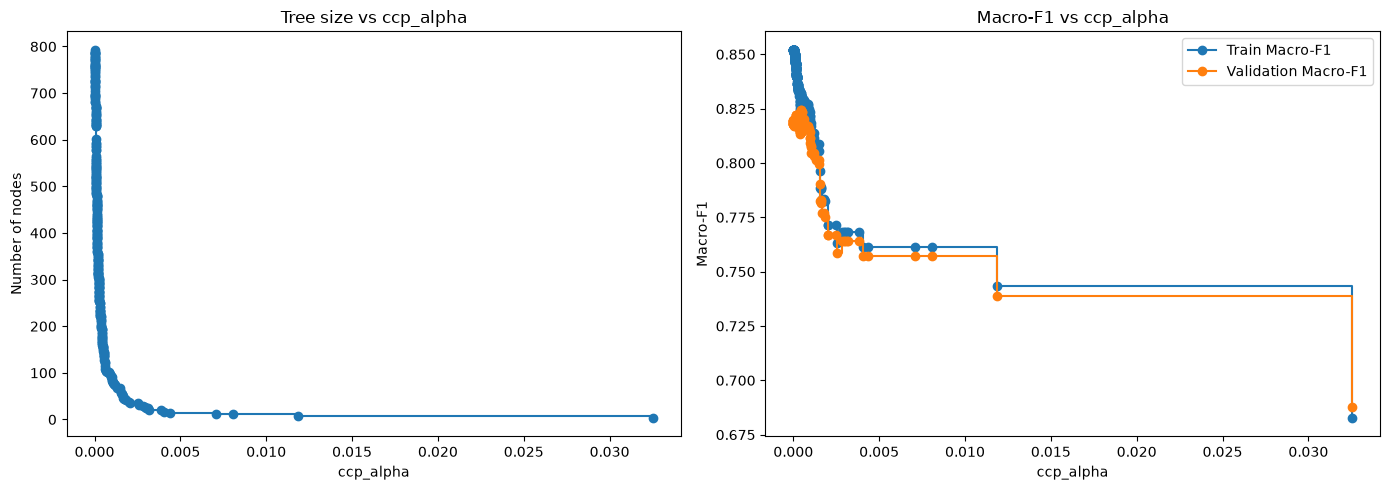

Best ccp_alpha by validation Macro-F1: 0.000444 (val F1=0.8245, nodes=165)


In [ ]:
# --- Cost-Complexity Pruning Path (model optimization technique, bonus) ---
prep_for_path = clone(preparation).fit(X_train, y_train)
X_train_path = prep_for_path.transform(X_train)
X_val_path = prep_for_path.transform(X_val)

path = dtl_scikit.cost_complexity_pruning_path(X_train_path, y_train)
ccp_alphas = path.ccp_alphas[:-1]  # drop the trivial last alpha (root-only tree)

trees = [
    clone(dtl_scikit).set_params(ccp_alpha=alpha).fit(X_train_path, y_train)
    for alpha in ccp_alphas
]
node_counts = [tree.tree_.node_count for tree in trees]
train_f1 = [f1_score(y_train, tree.predict(X_train_path), average='macro') for tree in trees]
val_f1 = [f1_score(y_val, tree.predict(X_val_path), average='macro') for tree in trees]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ccp_alphas, node_counts, marker='o', drawstyle='steps-post')
axes[0].set_xlabel('ccp_alpha')
axes[0].set_ylabel('Number of nodes')
axes[0].set_title('Tree size vs ccp_alpha')

axes[1].plot(ccp_alphas, train_f1, marker='o', label='Train Macro-F1', drawstyle='steps-post')
axes[1].plot(ccp_alphas, val_f1, marker='o', label='Validation Macro-F1', drawstyle='steps-post')
axes[1].set_xlabel('ccp_alpha')
axes[1].set_ylabel('Macro-F1')
axes[1].set_title('Macro-F1 vs ccp_alpha')
axes[1].legend()

plt.tight_layout()
plt.show()

best_idx = int(np.argmax(val_f1))
print(f'Best ccp_alpha by validation Macro-F1: {ccp_alphas[best_idx]:.6f} '
      f'(val F1={val_f1[best_idx]:.4f}, nodes={node_counts[best_idx]})')

**Insights**

Nilai `ccp_alpha` terbaik berdasarkan *macro-F1* validasi adalah 0,000444, dengan *macro-F1* 0,8245 dan 165 simpul. Hasil ini menunjukkan bahwa *pruning* ringan dapat memperkecil pohon secara signifikan tanpa banyak menurunkan kinerja, sehingga rentang `ccp_alpha` yang kecil layak dicoba saat penyetelan.

## SVM

Model Support Vector Machine pada variabel `svc`.

In [ ]:
svc_scikit = SVC(class_weight="balanced", kernel="rbf")
svc_scikit

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## Logistic Regression

Model Logistic Regression pada variabel `lr`.

In [ ]:
lr_scikit = SklearnLogisticRegression(class_weight="balanced", solver='liblinear', max_iter=150)
lr_scikit

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",150
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength

## Gaussian NB

Model Gaussian Naive Bayes pada variabel `gnb`.

In [ ]:
gnb_scikit = GaussianNB(var_smoothing=1e-8)
gnb_scikit

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-08
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

Bagian ini membandingkan hasil validasi seluruh model.

In [ ]:
models_scikit = {'knn': knn_scikit, 
                 'dtl': dtl_scikit, 
                 'svc': svc_scikit, 
                 'lr': lr_scikit, 
                 'gnb': gnb_scikit}
models_scikit

{'knn': KNeighborsClassifier(),
 'dtl': DecisionTreeClassifier(class_weight='balanced', max_depth=10),
 'svc': SVC(class_weight='balanced'),
 'lr': LogisticRegression(class_weight='balanced', max_iter=150, solver='liblinear'),
 'gnb': GaussianNB(var_smoothing=1e-08)}

In [ ]:
for model in models_scikit : 
    print (model)
    fit_predict (models_scikit[model], X_train, y_train, X_val)

holdout_table_scikit = holdout(models_scikit, X_train, y_train, X_val, y_val, method=None)   
holdout_table_scikit

knn
dtl
svc
lr
gnb


,holdout
knn,0.725124
dtl,0.818153
svc,0.683068
lr,0.757536
gnb,0.447423


In [ ]:
kfold_table_scikit = kfold(models_scikit, X_train, y_train)
kfold_table_scikit

,kfold_mean,kfold_std
knn,0.717417,0.007133
dtl,0.812227,0.006392
svc,0.682815,0.004302
lr,0.755836,0.005799
gnb,0.444067,0.010984


In [ ]:
compare(holdout_table_scikit, kfold_table_scikit)

,holdout,kfold_mean,kfold_std
dtl,0.818153,0.812227,0.006392
lr,0.757536,0.755836,0.005799
knn,0.725124,0.717417,0.007133
svc,0.683068,0.682815,0.004302
gnb,0.447423,0.444067,0.010984


**Insights**

Pada model `scikit-learn`, DTL kembali menjadi yang terbaik (*holdout* 0,818 dan *cross-validation* 0,812), diikuti Logistic Regression (0,758), KNN (0,725), SVM (0,683), dan Gaussian Naive Bayes (0,447). DTL buatan sendiri memperoleh skor yang lebih tinggi daripada DTL `scikit-learn`, yang memakai konfigurasi berbeda, yaitu kedalaman maksimum 10 dan pembobotan kelas seimbang. KNN buatan sendiri memperoleh skor yang hampir sama dengan KNN `scikit-learn`.

## Mutual Information Check

Korelasi Pearson hanya menangkap hubungan linear, sehingga kurang mencerminkan fitur berbentuk ambang atau nonlinear seperti `is_zero_night_stay` dan `is_last_minute`. *Mutual information* juga menangkap ketergantungan nonlinear, sehingga diperiksa per fitur sebagai pelengkap uji ablasi di bawah, yang mengukur pengaruh fitur terhadap *macro-F1* setiap model.

In [ ]:
mi_scores = mutual_info_classif(
    X_train_prepared, y_train, discrete_features='auto', random_state=CFG.SEED,
)
mi_table = pd.Series(mi_scores, index=X_train_prepared.columns, name='mutual_info').sort_values(ascending=False)
mi_table

scale__log_days_before_arrival                    0.103631
remainder__arrival_date                           0.092717
remainder__days_before_arrival_bucket             0.090184
remainder__is_far_advance                         0.057042
remainder__booking_date                           0.039139
scale__special_requests                           0.037890
remainder__price_vs_room_median                   0.028278
scale__rate_per_guest_night                       0.024026
remainder__is_last_minute                         0.020732
scale__log_nightly_rate_idr                       0.020489
scale__arrival_year                               0.019659
remainder__month_cos                              0.018983
remainder__room_category_Type C                   0.010529
scale__log_total_nights                           0.009912
scale__log_total_prior_bookings                   0.009817
remainder__booking_channel_Corporate              0.008404
scale__total_guests                               0.0073

**Insights**

Fitur dengan *mutual information* tertinggi adalah `log_days_before_arrival` (0,104), `arrival_date` (0,093), `days_before_arrival_bucket` (0,090), dan `is_far_advance` (0,057). Hal ini menegaskan bahwa jarak pemesanan merupakan sinyal terkuat terhadap pembatalan. Sebaliknya, `is_zero_night_stay` memiliki *mutual information* yang sangat kecil (0,002) karena hanya sedikit pesanan yang tidak memiliki malam menginap.

## Feature Engineering Ablation

Fitur turunan baru (`is_zero_night_stay`, `days_before_arrival_bucket`, `is_last_minute`, `is_far_advance`, dan `price_vs_room_median`) memiliki korelasi Pearson yang mendekati nol terhadap target. Karena korelasi Pearson hanya menangkap hubungan linear, skor yang rendah belum tentu berarti fitur tersebut hanya *noise*. Oleh karena itu, pengaruhnya diperiksa langsung terhadap *macro-F1*.

In [ ]:
preparation_with = Pipeline([
    ('clean', DataCleaner()),
    ('construct', AttributeConstructor(include_new_features=True)),
    ('encode', FeatureEncoder()),
    ('scale', scale_transformer),
])
preparation_without = Pipeline([
    ('clean', DataCleaner()),
    ('construct', AttributeConstructor(include_new_features=False)),
    ('encode', FeatureEncoder()),
    ('scale', scale_transformer),
])

def kfold_with_prep(prep, model, X, y):
    folds = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
    scores = []
    for fit_idx, eval_idx in folds.split(X, y):
        pipeline = Pipeline([('preparation', clone(prep)), ('model', clone(model))])
        pipeline.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        pred = pipeline.predict(X.iloc[eval_idx])
        scores.append(f1_score(y.iloc[eval_idx], pred, average='macro'))
    return np.array(scores)

ablation_rows = []
for name, model in models_scikit.items():
    with_score = kfold_with_prep(preparation_with, model, X_train, y_train).mean()
    without_score = kfold_with_prep(preparation_without, model, X_train, y_train).mean()
    ablation_rows.append({
        'model': name, 'with_new_features': with_score,
        'without_new_features': without_score, 'diff': with_score - without_score,
    })

ablation_table = pd.DataFrame(ablation_rows).set_index('model')
ablation_table

,with_new_features,without_new_features,diff
model,,,
knn,0.738238,0.738187,0.000051
dtl,0.812731,0.813658,-0.000928
svc,0.692124,0.692111,0.000013
lr,0.755836,0.755807,0.000029
gnb,0.444067,0.394970,0.049097


**Insights**

Penambahan fitur turunan baru hampir tidak mengubah *macro-F1* pada KNN, DTL, SVM, dan Logistic Regression, dengan selisih kurang dari 0,001. Peningkatan yang berarti hanya terlihat pada Gaussian Naive Bayes, yaitu sekitar 0,049. Karena fitur-fitur tersebut tidak menurunkan kinerja model lain, fitur tetap dipertahankan.

## Improvements (Optional)

Bagian ini membahas penyetelan hiperparameter, *cross-validation*, dan visualisasi tambahan.

In [ ]:
gridKNN_scikit = {
    'n_neighbors': [7, 27, 23, 19], 
    'metric': ['euclidean', 'minkowski'], 
    'p': [1, 2],
    'weights': ['distance']
}
knn_tuned_scikit = tune (models_scikit['knn'], gridKNN_scikit, X_train, y_train)
knn_tuned_scikit

[I 2026-11-23 20:47:30,435] A new study created in memory with name: knn
[I 2026-11-23 20:47:31,162] Trial 0 finished with value: 0.7218406541788974 and parameters: {'n_neighbors': 55, 'weights': 'distance', 'metric': 'euclidean', 'p': 1}. Best is trial 0 with value: 0.7218406541788974.
[I 2026-11-23 20:47:31,627] Trial 1 finished with value: 0.7174174988381272 and parameters: {'n_neighbors': 5, 'weights': 'uniform', 'metric': 'euclidean', 'p': 2}. Best is trial 0 with value: 0.7218406541788974.
[I 2026-11-23 20:47:32,195] Trial 2 finished with value: 0.7035217336115662 and parameters: {'n_neighbors': 49, 'weights': 'uniform', 'metric': 'minkowski', 'p': 2}. Best is trial 0 with value: 0.7218406541788974.
[I 2026-11-23 20:47:32,895] Trial 3 finished with value: 0.6911695301393571 and parameters: {'n_neighbors': 95, 'weights': 'uniform', 'metric': 'minkowski', 'p': 1}. Best is trial 0 with value: 0.7218406541788974.
[I 2026-11-23 20:47:33,423] Trial 4 finished with value: 0.720837839613

,n_neighbors,weights,metric,p,kfold_mean,kfold_std
18,81,distance,euclidean,2,0.723652,0.005258
20,81,distance,euclidean,2,0.723652,0.005258
11,87,distance,euclidean,2,0.723558,0.004616
22,87,distance,euclidean,2,0.723558,0.004616
21,79,distance,euclidean,2,0.723452,0.005389
12,97,distance,euclidean,2,0.723430,0.005066
13,97,distance,euclidean,2,0.723430,0.005066
14,83,distance,minkowski,2,0.723420,0.005183
10,61,distance,euclidean,2,0.723124,0.005571
6,35,distance,euclidean,2,0.723110,0.005558


In [ ]:
gridDTL_scikit = {
    'max_depth': [10, 11, 13, 12],
    'min_samples_split': [2, 9, 10, 11, 16],
    'min_samples_leaf': [1, 6],
    'ccp_alpha': [0.000079, 0],
}
dtl_tuned_scikit = tune(models_scikit['dtl'], gridDTL_scikit, X_train, y_train)

[I 2026-11-23 20:47:49,941] A new study created in memory with name: dtl
[I 2026-11-23 20:47:50,972] Trial 0 finished with value: 0.791849041199295 and parameters: {'max_depth': 28, 'min_samples_split': 5, 'min_samples_leaf': 9}. Best is trial 0 with value: 0.791849041199295.
[I 2026-11-23 20:47:51,899] Trial 1 finished with value: 0.791623856957818 and parameters: {'max_depth': 47, 'min_samples_split': 3, 'min_samples_leaf': 8}. Best is trial 0 with value: 0.791849041199295.
[I 2026-11-23 20:47:52,827] Trial 2 finished with value: 0.7937664905256882 and parameters: {'max_depth': 23, 'min_samples_split': 9, 'min_samples_leaf': 8}. Best is trial 2 with value: 0.7937664905256882.
[I 2026-11-23 20:47:53,755] Trial 3 finished with value: 0.7955694150038314 and parameters: {'max_depth': 24, 'min_samples_split': 18, 'min_samples_leaf': 6}. Best is trial 3 with value: 0.7955694150038314.
[I 2026-11-23 20:47:54,814] Trial 4 finished with value: 0.7920855206664247 and parameters: {'max_depth': 

,max_depth,min_samples_split,min_samples_leaf,kfold_mean,kfold_std
27,13,4,1,0.810573,0.005446
23,11,2,1,0.810551,0.004813
22,14,3,1,0.810286,0.004279
11,12,5,1,0.809067,0.005323
10,17,2,1,0.808948,0.005358
6,19,3,2,0.807773,0.005385
14,7,4,5,0.807737,0.007781
12,9,9,3,0.807189,0.006695
24,14,6,2,0.807163,0.003844
21,22,3,1,0.807121,0.004628


In [ ]:
gridSVM_scikit ={
    'kernel' : ['rbf'],
    'C' : [0.001, 1, 30],
    'gamma' : ['scale', 0.01, 0.1]
}
svc_tuned_scikit = tune(models_scikit['svc'], gridSVM_scikit, X_train, y_train)

[I 2026-11-23 20:48:17,822] A new study created in memory with name: svc
[I 2026-11-23 20:49:14,696] Trial 0 finished with value: 0.6751760786902576 and parameters: {'C': 142.07412336070624, 'gamma': 'scale'}. Best is trial 0 with value: 0.6751760786902576.
[I 2026-11-23 20:49:58,036] Trial 1 finished with value: 0.6794748966837608 and parameters: {'C': 3.6494681661538926, 'gamma': 'scale'}. Best is trial 1 with value: 0.6794748966837608.
[I 2026-11-23 20:51:10,433] Trial 2 finished with value: 0.308847594797829 and parameters: {'C': 0.004414612813056492, 'gamma': 'auto'}. Best is trial 1 with value: 0.6794748966837608.
[I 2026-11-23 20:53:18,139] Trial 3 finished with value: 0.6696152925822849 and parameters: {'C': 6.703725712007921, 'gamma': 'auto'}. Best is trial 1 with value: 0.6794748966837608.
[I 2026-11-23 20:54:46,757] Trial 4 finished with value: 0.5008107691178927 and parameters: {'C': 0.042105791566271436, 'gamma': 'auto'}. Best is trial 1 with value: 0.6794748966837608.
[I 

,C,gamma,kfold_mean,kfold_std
1,3.649468,scale,0.679475,0.005591
6,0.001858,scale,0.677841,0.003704
0,142.074123,scale,0.675176,0.007759
8,3.579472,auto,0.672235,0.006332
3,6.703726,auto,0.669615,0.006647
5,408.984565,auto,0.665769,0.006638
7,0.046236,auto,0.560903,0.064600
4,0.042106,auto,0.500811,0.079627
9,0.002210,auto,0.370977,0.062094
2,0.004415,auto,0.308848,0.076043


In [ ]:
gridLR_scikit = {
    'max_iter': [50, 62, 100, 143],
    'penalty': ['l2'],
    'C': [0.001, 0.1, 20, 80]
}
lr_tuned_scikit = tune(models_scikit['lr'], gridLR_scikit, X_train, y_train)

[I 2026-11-23 21:01:06,416] A new study created in memory with name: lr
c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_b

,C,max_iter,penalty,kfold_mean,kfold_std
17,0.019553,99,l2,0.757928,0.004177
21,0.022506,94,l2,0.757901,0.004533
9,0.042664,111,l1,0.757741,0.004479
26,0.033739,169,l2,0.757340,0.004682
16,0.014711,93,l2,0.757059,0.003848
11,0.110226,130,l2,0.756397,0.005715
13,0.287672,131,l2,0.756267,0.005683
7,5.926297,117,l2,0.756226,0.005831
5,7.161823,104,l2,0.756076,0.005733
23,3.544397,60,l2,0.755927,0.005509


In [ ]:
gridGNB_scikit ={
    'var_smoothing': [1e-9, 1e-3]
}
gnb_tuned_scikit = tune(models_scikit['gnb'], gridGNB_scikit, X_train, y_train)

[I 2026-11-23 21:01:52,269] A new study created in memory with name: gnb
[I 2026-11-23 21:01:52,758] Trial 0 finished with value: 0.4322768060861678 and parameters: {'var_smoothing': 1.2989625098233701e-12}. Best is trial 0 with value: 0.4322768060861678.
[I 2026-11-23 21:01:53,189] Trial 1 finished with value: 0.4461081397257291 and parameters: {'var_smoothing': 1.7778392649360823e-08}. Best is trial 1 with value: 0.4461081397257291.
[I 2026-11-23 21:01:53,601] Trial 2 finished with value: 0.43854843583035397 and parameters: {'var_smoothing': 1.044757787241826e-10}. Best is trial 1 with value: 0.4461081397257291.
[I 2026-11-23 21:01:54,024] Trial 3 finished with value: 0.4392434827224562 and parameters: {'var_smoothing': 6.977191861983916e-10}. Best is trial 1 with value: 0.4461081397257291.
[I 2026-11-23 21:01:54,422] Trial 4 finished with value: 0.4322768060861678 and parameters: {'var_smoothing': 1.2664708830752795e-12}. Best is trial 1 with value: 0.4461081397257291.
[I 2026-11-23

,var_smoothing,kfold_mean,kfold_std
13,9.937608e-07,0.529417,0.015924
14,8.969892e-07,0.525666,0.015321
11,8.556928e-07,0.524421,0.015379
18,8.476323e-07,0.524409,0.015120
12,7.968773e-07,0.522311,0.015011
21,7.718199e-07,0.521242,0.015200
24,6.306287e-07,0.515450,0.014695
27,4.287701e-07,0.502880,0.014038
22,2.582208e-07,0.487240,0.013988
23,2.426414e-07,0.485173,0.014224


In [ ]:
tuned_models_scikit = {'knn': knn_tuned_scikit, 
                'dtl': dtl_tuned_scikit, 
                'svc': svc_tuned_scikit, 
                'lr': lr_tuned_scikit, 
                'gnb': gnb_tuned_scikit}
tuned_models_scikit

{'knn':     n_neighbors   weights     metric  p  kfold_mean  kfold_std
 18           81  distance  euclidean  2    0.723652   0.005258
 20           81  distance  euclidean  2    0.723652   0.005258
 11           87  distance  euclidean  2    0.723558   0.004616
 22           87  distance  euclidean  2    0.723558   0.004616
 21           79  distance  euclidean  2    0.723452   0.005389
 12           97  distance  euclidean  2    0.723430   0.005066
 13           97  distance  euclidean  2    0.723430   0.005066
 14           83  distance  minkowski  2    0.723420   0.005183
 10           61  distance  euclidean  2    0.723124   0.005571
 6            35  distance  euclidean  2    0.723110   0.005558
 9            83  distance  manhattan  1    0.723093   0.004176
 26           89  distance  manhattan  2    0.722864   0.003760
 15           75  distance  euclidean  1    0.722804   0.004457
 19           67  distance  minkowski  2    0.722306   0.005091
 28           67  distance  eucli

In [ ]:
tuning_results_scikit = {
    'knn': knn_tuned_scikit,
    'dtl': dtl_tuned_scikit,
    'svc': svc_tuned_scikit,
    'lr': lr_tuned_scikit,
    'gnb': gnb_tuned_scikit,
}

metric_columns = ['kfold_mean', 'kfold_std']
tuned_models_scikit = {
    name: clone(models_scikit[name]).set_params(
        **result.drop(columns=metric_columns).to_dict(orient='records')[0]
    )
    for name, result in tuning_results_scikit.items()
}

kfold_table_tuned_scikit = kfold(tuned_models_scikit, X_train, y_train)
kfold_table_tuned_scikit

holdout_table_tuned_scikit = holdout(tuned_models_scikit, X_train, y_train, X_val, y_val)
tuned_comparison_scikit = compare(holdout_table_tuned_scikit, kfold_table_tuned_scikit)

best_model_name_scikit = tuned_comparison_scikit.index[0]
tuned_comparison_scikit

c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 

,holdout,kfold_mean,kfold_std
dtl,0.821326,0.809483,0.003732
lr,0.757673,0.757928,0.004177
knn,0.731293,0.723652,0.005258
svc,0.677562,0.679475,0.005591
gnb,0.527807,0.529417,0.015924


In [ ]:
# Write your code here
tuned_comparison
tuned_comparison_scikit

,holdout,kfold_mean,kfold_std
dtl,0.821326,0.809483,0.003732
lr,0.757673,0.757928,0.004177
knn,0.731293,0.723652,0.005258
svc,0.677562,0.679475,0.005591
gnb,0.527807,0.529417,0.015924


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

Bagian ini menyimpan model yang telah dilatih dan memuatnya kembali untuk prediksi.

In [232]:
# Write your code here

def save_model(model, name):
    path = CFG.OUTPUT_DIR / f'{name}.pkl'
    joblib.dump(model, path)
    return path

def load_model(name):
    return joblib.load(CFG.OUTPUT_DIR / f'{name}.pkl')

In [233]:
# for name, model in models.items():
#     fitted = fit_model(model, X_train, y_train)
#     print(f'{name}: saved to {save_model(fitted, name)}')

# contoh : 
simpan_model = fit_model (models[best_model_name], X_train, y_train)
save_model(simpan_model, best_model_name)

WindowsPath('output/dtl.pkl')

---

# Kaggle Submission <a name="10"></a>

---

*Pipeline* dan model akhir dilatih pada seluruh data latih asli, sedangkan data uji hanya ditransformasikan. Berkas submisi berisi kolom `id` dan `is_canceled`.

In [234]:
# def submit(model, X, y, X_test, method=None):
#     predictions = fit_predict(model, X, y, X_test, method)
#     ids = test_df.loc[X_test.index, CFG.ID_COLUMN]
#     result = pd.DataFrame({CFG.ID_COLUMN: ids, CFG.TARGET: predictions})
#     assert len(result) == len(test_df)
#     path = CFG.OUTPUT_DIR / 'submission.csv'
#     result.to_csv(path, index=False)
#     print(f'{len(result)} rows written to {path}')
#     return result.head()

def submit(model, X, y, X_test, X_val=X_val, y_val=y_val, method=None):
    predictions = fit_predict(model, X, y, X_test, method)

    val_predictions = fit_predict(
        model,
        X_train,
        y_train,
        X_val,
        method,
    )

    val_f1 = f1_score(
        y_val,
        val_predictions,
        average="macro",
    )

    ids = test_df.loc[X_test.index, CFG.ID_COLUMN]
    result = pd.DataFrame({
        CFG.ID_COLUMN: ids,
        CFG.TARGET: predictions,
    })

    print(f"{type(model).__name__} Holdout Macro-F1: {val_f1:.6f}")

    assert len(result) == len(test_df)

    path = CFG.OUTPUT_DIR / "submission.csv"
    result.to_csv(path, index=False)

    print(f"{len(result)} rows written to {path}")
    return result.head()

submit (models[best_model_name], X, y, X_test)

DecisionTreeCART Holdout Macro-F1: 0.831665
6844 rows written to output\submission.csv


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

Analisis ini mendukung setiap langkah yang diambil pada notebook ini.

### Confusion Matrix

Confusion matrix serta precision dan recall kelima model.

In [237]:
def confusion(models, X_train, y_train, X_val, y_val, method=None):
    figure, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.6), squeeze=False)

    for axis, (name, model) in zip(axes.flat, models.items()):
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        ConfusionMatrixDisplay.from_predictions(y_val, predicted, ax=axis, colorbar=False)
        axis.set_title(name)

    plt.tight_layout()
    plt.show()

def report(models, X_train, y_train, X_val, y_val, method=None):
    tables = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        tables[name] = pd.DataFrame(classification_report(y_val, predicted, output_dict=True)).T

    return pd.concat(tables)

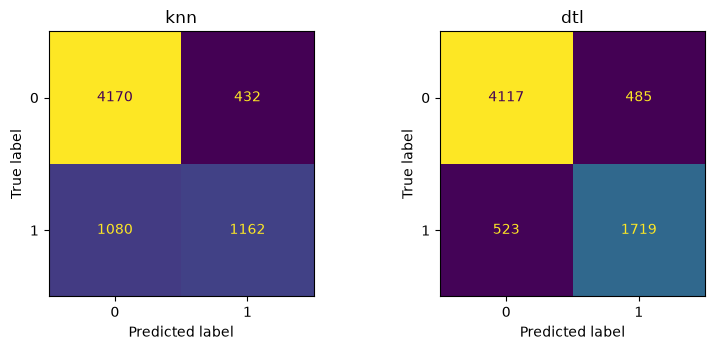

In [238]:
confusion (models, X_train, y_train, X_val, y_val)
# confusion (tuned_models_scikit, X_train, y_train, X_val, y_val)

In [240]:
report (models, X_train, y_train, X_val, y_val)
# report (tuned_models_scikit, X_train, y_train, X_val, y_val)

precision    recall  f1-score      support
knn 0              0.794286  0.906128  0.846529  4602.000000
    1              0.728984  0.518287  0.605839  2242.000000
    accuracy       0.779077  0.779077  0.779077     0.779077
    macro avg      0.761635  0.712208  0.726184  6844.000000
    weighted avg   0.772894  0.779077  0.767682  6844.000000
dtl 0              0.886760  0.895046  0.890884  4602.000000
    1              0.780355  0.765388  0.772799  2242.000000
    accuracy       0.852572  0.852572  0.852572     0.852572
    macro avg      0.833557  0.830217  0.831841  6844.000000
    weighted avg   0.851903  0.852572  0.852201  6844.000000

**Insights**

DTL memperoleh F1 0,891 pada kelas tidak dibatalkan dan 0,773 pada kelas dibatalkan, dengan akurasi 0,853. *Recall* kelas dibatalkan lebih rendah daripada kelas tidak dibatalkan, artinya model lebih sering melewatkan pesanan yang akan dibatalkan. Ketimpangan ini jauh lebih besar pada KNN, yang hanya mengenali 51,8% pesanan yang dibatalkan.

### Misclassified Patterns

Baris asli `train` yang salah diprediksi oleh model terbaik.

In [241]:
def misclassified(model, X_train, y_train, X_val, y_val, method=None):
    predicted = pd.Series(fit_predict(model, X_train, y_train, X_val, method), index=X_val.index)
    wrong = predicted[predicted != y_val]
    return train_df.loc[wrong.index].assign(predicted=wrong)

In [242]:
misclassified(models[best_model_name], X_train, y_train, X_val, y_val)
# misclassified(tuned_models_scikit[best_model_name_scikit], X_train, y_train, X_val, y_val)

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled,predicted
11890,6b96581c,1.0,0.0,2,1,Half Board,0.0,Type B,104.0,2023,7,18,Offline Agent,0,0,0,NaN,0.0,0,1
17852,e7797a98,2.0,0.0,2,0,Room Only,0.0,Type B,0.0,2024,11,12,Online Travel Agent,0,0,0,1559000.0,NaN,1,0
19278,9310b01a,2.0,0.0,0,4,Room Only,0.0,Type B,35.0,2024,2,24,Online Travel Agent,0,0,0,1120000.0,1.0,1,0
16333,c96e41c1,3.0,0.0,1,0,Breakfast,0.0,Type G,25.0,2024,9,17,Online Travel Agent,0,0,0,3087000.0,0.0,0,1
13190,d71b24d2,2.0,0.0,1,2,Breakfast,0.0,Type B,101.0,2024,3,24,Online Travel Agent,0,0,0,1576000.0,1.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4412,aadfab63,2.0,NaN,0,2,Breakfast,0.0,Type G,26.0,2024,8,23,Online Travel Agent,0,0,0,2429000.0,1.0,1,0
1324,c01363dd,1.0,0.0,1,4,Breakfast,0.0,Type B,189.0,2024,7,24,Online Travel Agent,0,0,0,1450000.0,0.0,1,0
4696,a340119a,2.0,0.0,1,1,Breakfast,0.0,Type B,44.0,2024,11,18,Online Travel Agent,0,0,0,1586000.0,1.0,1,0
23627,78a42caf,1.0,0.0,2,7,Breakfast,0.0,Type B,75.0,2024,6,9,Online Travel Agent,0,0,0,2224000.0,0.0,1,0


**Insights**

Sebanyak 1.011 dari 6.844 baris validasi salah diprediksi oleh DTL. Baris-baris ini dapat ditinjau berdasarkan karakteristiknya, misalnya jarak pemesanan, harga, dan saluran pemesanan, untuk menemukan pola kesalahan yang dapat menjadi dasar perbaikan fitur atau model.